Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

 TABLA 1: ESTADÍSTICAS DESCRIPTIVAS DEL PANEL (Ventana ±14 días)
       Y_grocery  Y_residential   Y_parks  Exposure  ATM_Density
count   1593.000       1593.000  1456.000  1593.000     1593.000
mean      12.731          4.260   164.327     0.303       93.844
std       12.335          5.158    72.782     0.095       20.303
min      -42.000        -11.000   -25.000     0.175       67.143
max       94.000         21.000   500.000     0.475      135.962
--------------------------------------------------------------------------------

 TABLA 1b: EFECTO CAUSAL (DiD Simple sin Efectos Fijos)
            Coeficiente  Std.Error  P-value
const          10.622**     5.2872   0.0447
Shock_x_Exp    -14.1611    16.0742   0.3785
Shock_t         -0.5823     4.5371   0.8979
Exposure         7.0576    20.3948   0.7294
R-squared (Within): 0.0011 | Observations: 1593
---------

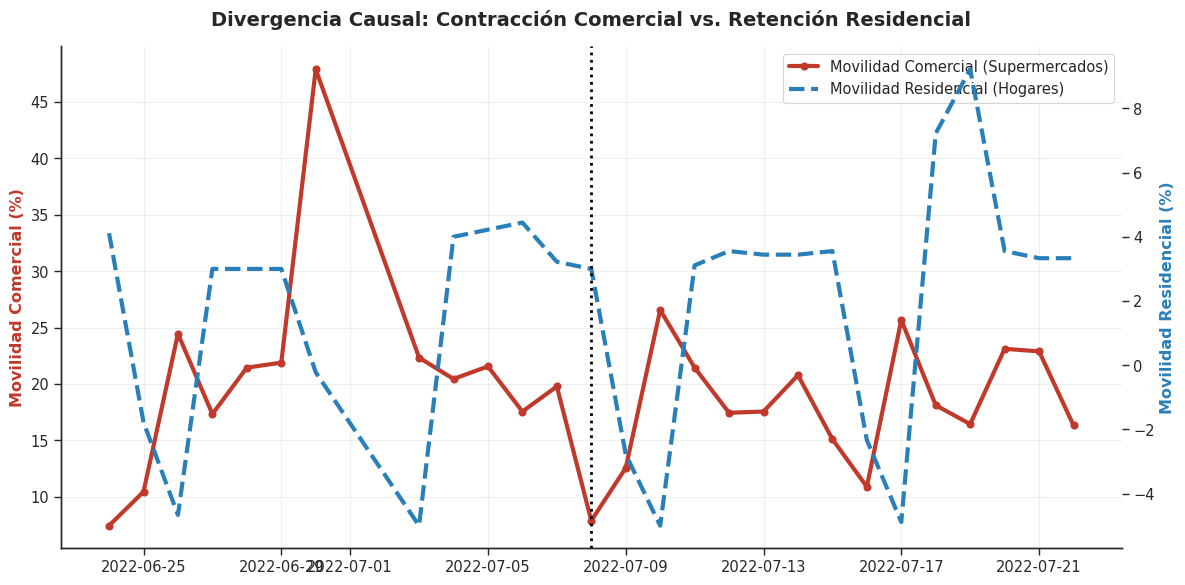

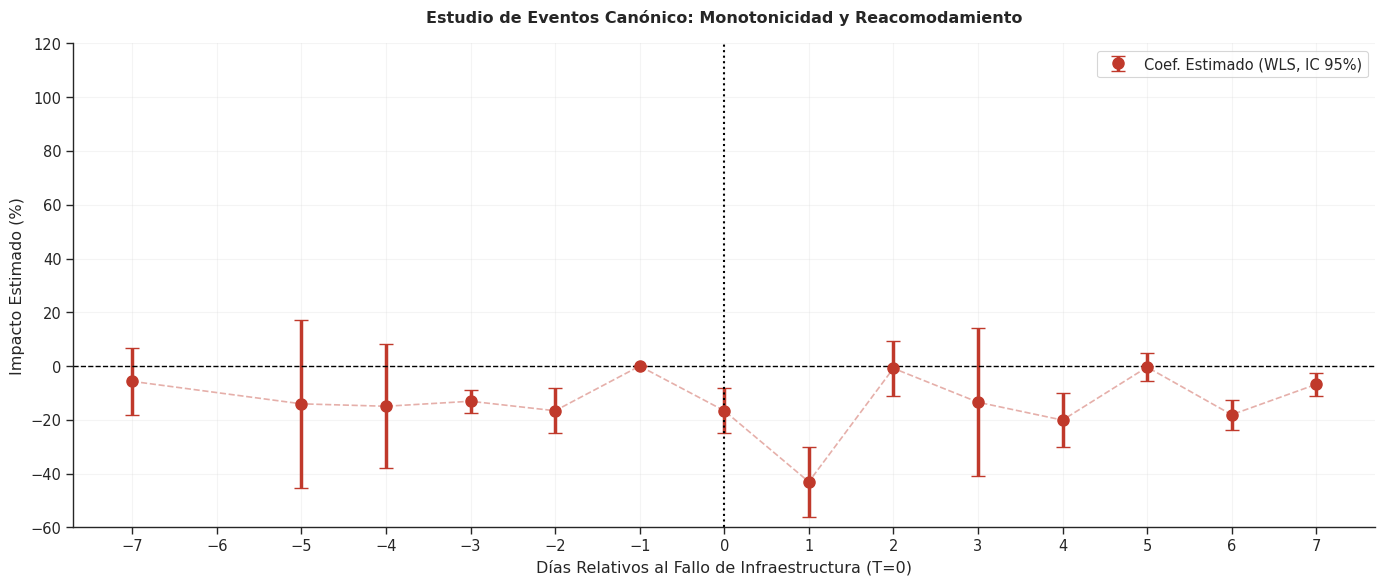

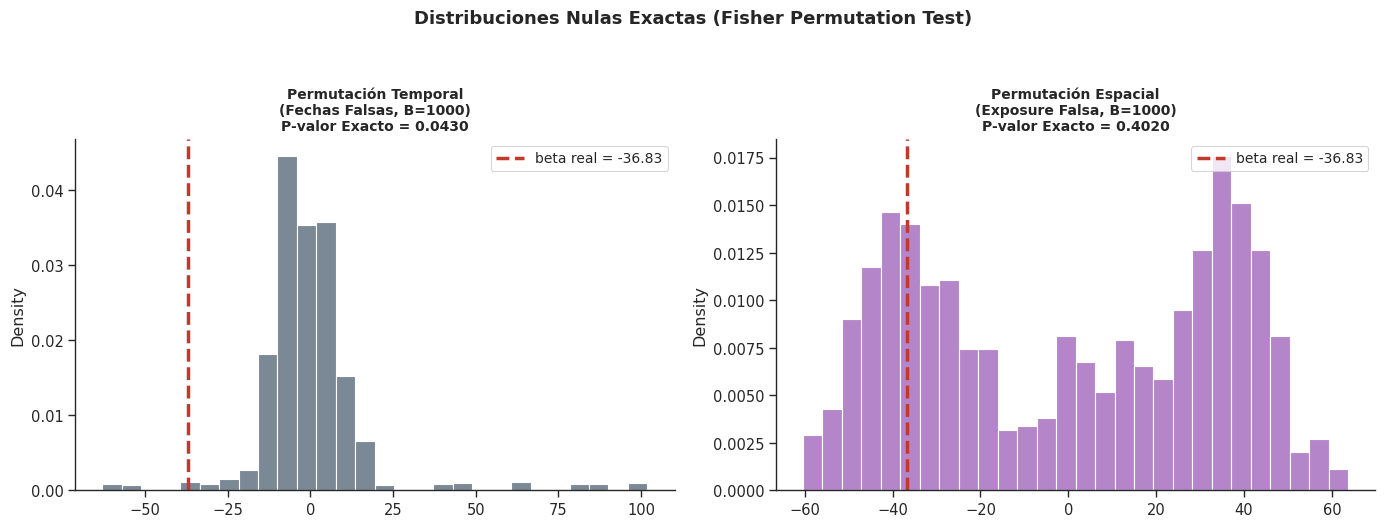

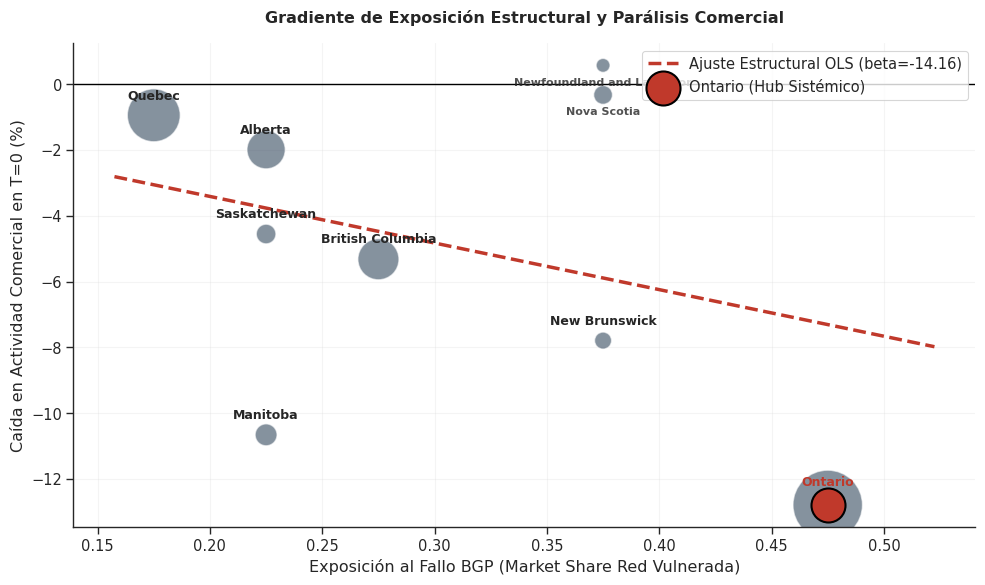

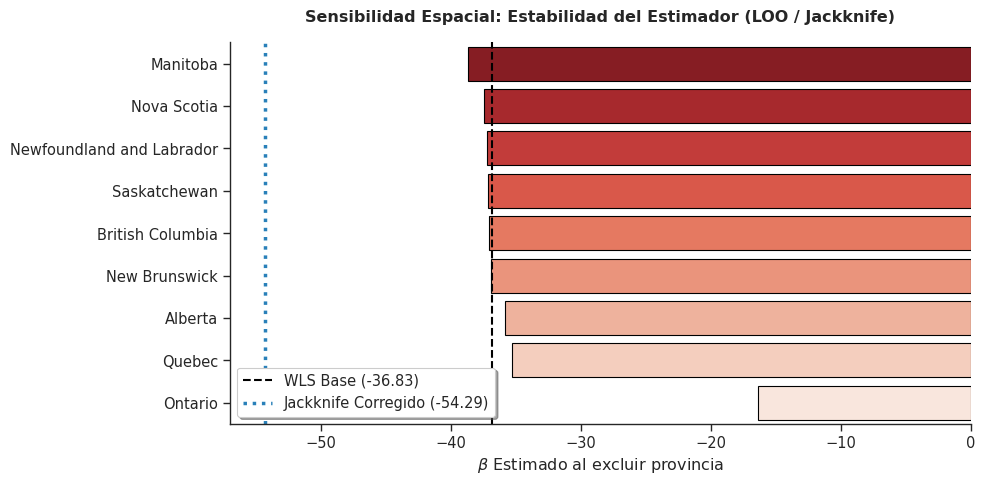

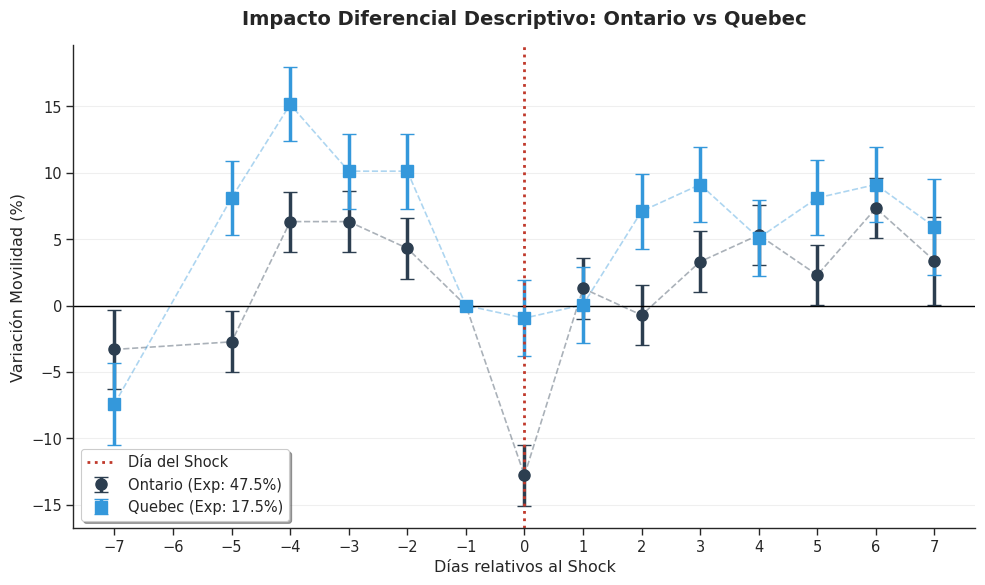

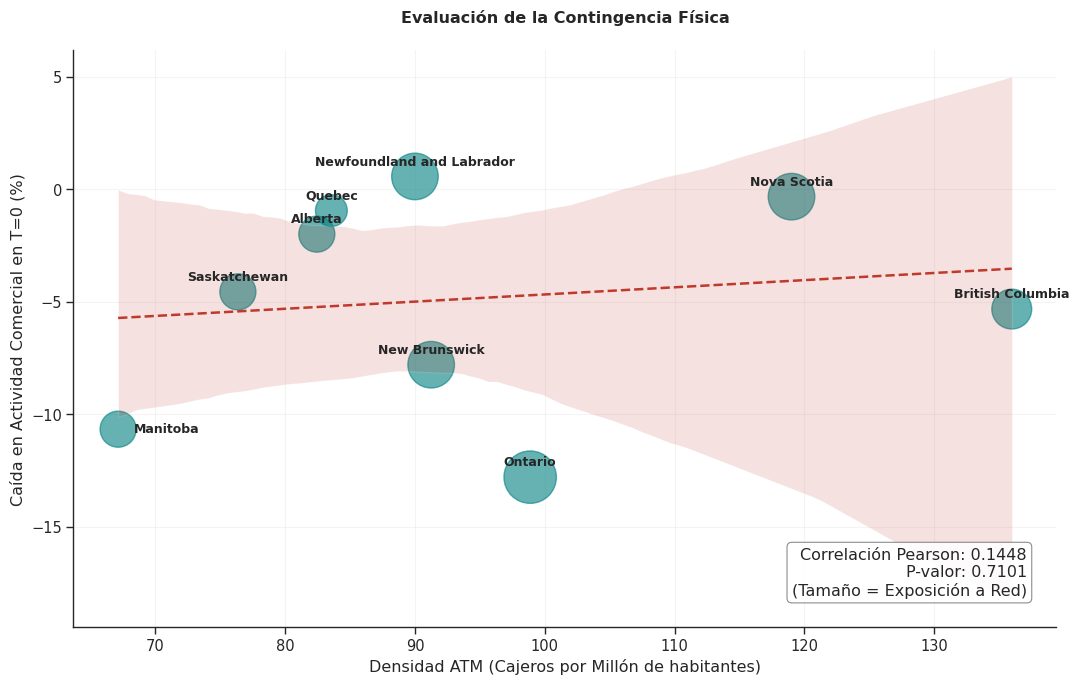

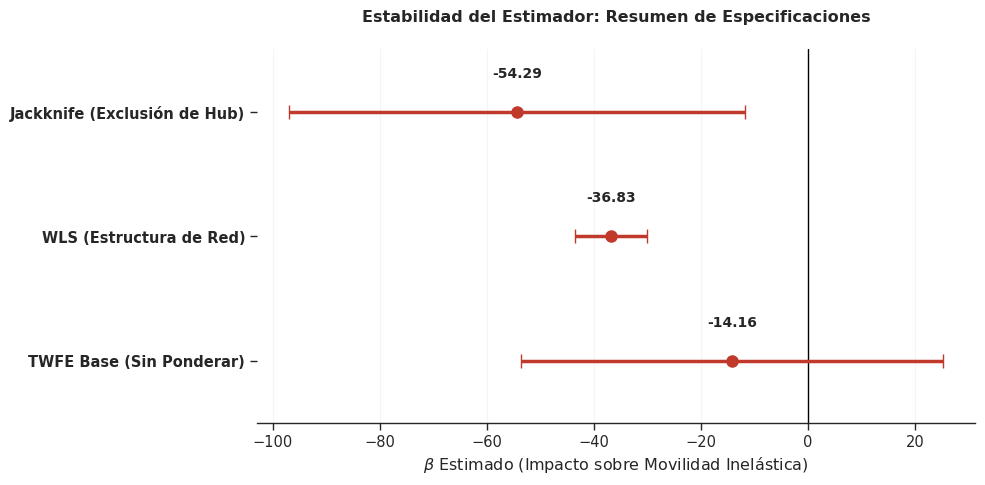

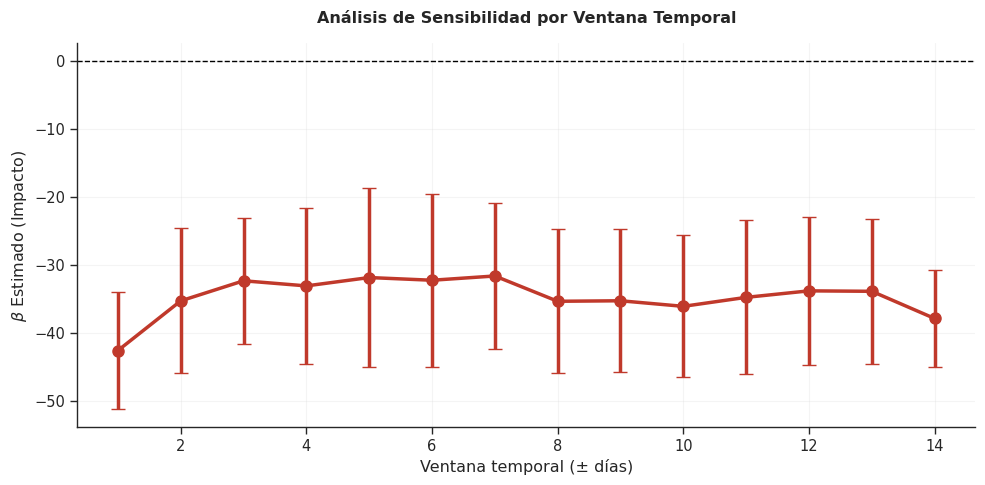

In [9]:
# TESINA LICENCIATURA: SHOCK DE INFRAESTRUCTURA DE PAGOS (ROGERS 2022)

import subprocess, sys, os, gc, warnings
import numpy as np
import pandas as pd
import polars as pl
import statsmodels.api as sm
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats as scipy_stats
from scipy.stats import pearsonr
from scipy.optimize import minimize

def install_silent(package):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

try:
    from linearmodels.panel import PanelOLS
except ImportError:
    install_silent('linearmodels')
    from linearmodels.panel import PanelOLS

warnings.filterwarnings('ignore')
sns.set_theme(style="ticks", context="paper", font_scale=1.2)
plt.rcParams.update({"font.family": "sans-serif", "axes.spines.top": False, "axes.spines.right": False})
os.makedirs("figures", exist_ok=True)

def bh_correction(pvalues: dict) -> pd.DataFrame:
    names  = list(pvalues.keys())
    pvals  = np.array(list(pvalues.values()))
    n      = len(pvals)
    order  = np.argsort(pvals)
    ranked = np.empty(n)
    ranked[order] = np.arange(1, n + 1)
    adj = np.minimum(1.0, pvals * n / ranked)
    for i in range(n - 2, -1, -1):
        adj[order[i]] = min(adj[order[i]], adj[order[i + 1]])
    return pd.DataFrame({"Outcome": names, "P-raw": np.round(pvals, 4), "P-BH (Adj)": np.round(adj, 4)})

def formatear_tabla_academica(res, titulo):
    df_res = pd.DataFrame({'Coeficiente': res.params, 'Std.Error': res.std_errors, 'P-value': res.pvalues})
    condiciones = [(df_res['P-value'] < 0.01), (df_res['P-value'] < 0.05), (df_res['P-value'] < 0.10)]
    df_res['Sig.'] = np.select(condiciones, ['***', '**', '*'], default='')
    df_res = df_res.round(4)
    df_res['Coeficiente'] = df_res['Coeficiente'].astype(str) + df_res['Sig.']
    print(f"\n{'='*80}\n {titulo}\n{'='*80}")
    print(df_res[['Coeficiente', 'Std.Error', 'P-value']])
    print(f"R-squared (Within): {res.rsquared_within:.4f} | Observations: {res.nobs}")
    print("-" * 80)


# MÓDULO 1: INGESTA Y PREPROCESAMIENTO
def prepare_data():
    try:
        from google.colab import drive
        drive.mount('/content/drive')
    except: pass

    archivos = [
        '/content/drive/MyDrive/Google_Mobility/2020_CA_Region_Mobility_Report.csv',
        '/content/drive/MyDrive/Google_Mobility/2021_CA_Region_Mobility_Report.csv',
        '/content/drive/MyDrive/Google_Mobility/2022_CA_Region_Mobility_Report.csv'
    ]
    dict_renombres = {
        'grocery_and_pharmacy_percent_change_from_baseline': 'Y_grocery',
        'parks_percent_change_from_baseline': 'Y_parks',
        'residential_percent_change_from_baseline': 'Y_residential',
        'transit_stations_percent_change_from_baseline': 'Y_transit'
    }

    df = (
        pl.scan_csv(archivos)
        .filter(pl.col("country_region") == "Canada")
        .filter(pl.col("sub_region_1").is_not_null())
        .filter(pl.col("sub_region_2").is_null())
        .filter(pl.col("metro_area").is_null())
        .with_columns(pl.col("date").str.strptime(pl.Date, "%Y-%m-%d"))
        .select(["date", "sub_region_1"] + list(dict_renombres.keys()))
        .rename(dict_renombres)
        .collect()
        .to_pandas()
    )

    df['date'] = pd.to_datetime(df['date'])

    df = df[df['date'].dt.month.isin([6, 7])]
    df = df[~((df['date'].dt.month == 7) & (df['date'].dt.day.isin([1, 2])))]
    df = df.set_index(['sub_region_1', 'date'])
    fechas_indice = df.index.get_level_values('date')
    df['Shock_t'] = (fechas_indice == '2022-07-08').astype(int)

    market_share_rogers = {
        'Ontario': 0.475, 'Nova Scotia': 0.375, 'New Brunswick': 0.375,
        'Newfoundland and Labrador': 0.375, 'British Columbia': 0.275,
        'Alberta': 0.225, 'Manitoba': 0.225, 'Saskatchewan': 0.225, 'Quebec': 0.175
    }
    df['Exposure'] = df.index.get_level_values('sub_region_1').map(market_share_rogers)
    df_base = df.dropna(subset=['Y_grocery', 'Exposure']).copy()
    df_base['Shock_x_Exp'] = df_base['Shock_t'] * df_base['Exposure']

    provincias_geo = {'Alberta': 4.5, 'British Columbia': 5.2, 'Manitoba': 1.4, 'New Brunswick': 0.8, 'Newfoundland and Labrador': 0.5, 'Nova Scotia': 1.0, 'Ontario': 15.1, 'Quebec': 8.7, 'Saskatchewan': 1.1, 'Prince Edward Island': 0.17}
    mapeo_archivos = {'atms_Alberta.csv': 'Alberta', 'atms_britishcolumbia.csv': 'British Columbia', 'atms_manitoba.csv': 'Manitoba', 'atms_newbrunswick.csv': 'New Brunswick', 'atms_NewfoundlandandLabrador.csv': 'Newfoundland and Labrador', 'atms_NovaScotia.csv': 'Nova Scotia', 'atms_ontario.csv': 'Ontario', 'atms_quebec.csv': 'Quebec', 'atms_Saskatchewan.csv': 'Saskatchewan'}

    ruta_base = '/content/drive/MyDrive/Google_Mobility/'
    atm_counts = {}
    for f, prov in mapeo_archivos.items():
        try: atm_counts[prov] = len(pd.read_csv(os.path.join(ruta_base, f), usecols=[0], encoding='latin-1', on_bad_lines='skip'))
        except: atm_counts[prov] = np.nan

    df_geo = pd.DataFrame(list(atm_counts.items()), columns=['sub_region_1', 'Total_ATMs']).merge(pd.DataFrame(list(provincias_geo.items()), columns=['sub_region_1', 'Pop_M']), on="sub_region_1")
    df_geo["Total_ATMs"] = df_geo["Total_ATMs"].fillna(df_geo["Total_ATMs"].median())
    df_geo["ATM_Density"] = df_geo["Total_ATMs"] / df_geo["Pop_M"]
    df_geo["Std_ATM_Density"] = (df_geo["ATM_Density"] - df_geo["ATM_Density"].mean()) / df_geo["ATM_Density"].std()

    df_base = df_base.reset_index().merge(df_geo[["sub_region_1", "Std_ATM_Density", "ATM_Density", "Pop_M"]], on="sub_region_1", how="left").set_index(["sub_region_1", "date"])

    print("\n" + "="*80)
    print(" TABLA 1: ESTADÍSTICAS DESCRIPTIVAS DEL PANEL (Ventana ±14 días)")
    print("="*80)
    cols_desc = ['Y_grocery', 'Y_residential', 'Y_parks', 'Exposure', 'ATM_Density']
    print(df_base[cols_desc].describe().round(3).loc[['count', 'mean', 'std', 'min', 'max']])
    print("-" * 80)

    return df_base, df_geo, market_share_rogers


# MÓDULO 2: IDENTIFICACION CAUSAL
def run_main_identification(df_base, ms_rogers):

    # Tabla 1b: DiD Simple (Sin Efectos Fijos) para contraste
    exog_did = sm.add_constant(df_base[['Shock_x_Exp', 'Shock_t', 'Exposure']])
    res_did = PanelOLS(df_base['Y_grocery'], exog_did).fit(cov_type='clustered', cluster_entity=True)
    formatear_tabla_academica(res_did, "TABLA 1b: EFECTO CAUSAL (DiD Simple sin Efectos Fijos)")

    # Tabla 2: TWFE Puro
    res_main = PanelOLS(
        df_base['Y_grocery'], df_base[['Shock_x_Exp']],
        entity_effects=True, time_effects=True, drop_absorbed=True
    ).fit(cov_type='clustered', cluster_entity=True)
    formatear_tabla_academica(res_main, "TABLA 2: EFECTO CAUSAL BASE (TWFE, ±14 Días)")
    se_twfe = res_main.std_errors['Shock_x_Exp']

    # Tabla 2b: WLS
    res_wls = PanelOLS(
        df_base["Y_grocery"], df_base[['Shock_x_Exp']],
        weights=df_base['Pop_M'],
        entity_effects=True, time_effects=True, drop_absorbed=True
    ).fit(cov_type="clustered", cluster_entity=True)
    formatear_tabla_academica(res_wls, "TABLA 2b: EFECTO CAUSAL (Ponderado por Población)")
    beta_real = res_wls.params['Shock_x_Exp']

    # WCB Manual (Teorema FWL)
    p_val_wcb = np.nan
    try:
        df_w = df_base.reset_index().dropna(subset=['Y_grocery', 'Shock_x_Exp']).copy()

        gm_y = df_w['Y_grocery'].mean()
        df_w['Y_dem'] = (df_w['Y_grocery']
                         - df_w.groupby('sub_region_1')['Y_grocery'].transform('mean')
                         - df_w.groupby('date')['Y_grocery'].transform('mean')
                         + gm_y)
        gm_x = df_w['Shock_x_Exp'].mean()
        df_w['X_dem'] = (df_w['Shock_x_Exp']
                         - df_w.groupby('sub_region_1')['Shock_x_Exp'].transform('mean')
                         - df_w.groupby('date')['Shock_x_Exp'].transform('mean')
                         + gm_x)

        y_w = df_w['Y_dem'].values
        X_w = df_w['X_dem'].values.reshape(-1, 1)

        ols_fwl = sm.WLS(y_w, X_w, weights=df_w['Pop_M']).fit()
        u_null = df_w['Y_dem'].values
        t_obs = ols_fwl.tvalues[0]

        clusters = df_w['sub_region_1'].values
        unique_clusters = np.unique(clusters)
        webb_weights = np.array([-np.sqrt(1.5), -1, -np.sqrt(0.5), np.sqrt(0.5), 1, np.sqrt(1.5)])

        np.random.seed(83)
        B_wcb = 999
        t_boot = np.zeros(B_wcb)

        for b in range(B_wcb):
            weights_map = {c: np.random.choice(webb_weights) for c in unique_clusters}
            w_vec = np.array([weights_map[c] for c in clusters])
            y_boot = u_null * w_vec
            boot_res = sm.WLS(y_boot, X_w, weights=df_w['Pop_M']).fit()
            t_boot[b] = boot_res.tvalues[0]

        p_val_wcb = np.mean(np.abs(t_boot) >= np.abs(t_obs))
    except Exception as e:
        p_val_wcb = res_main.pvalues['Shock_x_Exp']

    # Fisher Espacial
    np.random.seed(237)
    B_spat = 1000
    spatial_betas = np.zeros(B_spat)
    provs = list(ms_rogers.keys())
    exp_vals = list(ms_rogers.values())
    prov_arr = df_base.index.get_level_values("sub_region_1").to_numpy()
    shock_arr = df_base["Shock_t"].to_numpy()

    for i in range(B_spat):
        mapping = dict(zip(provs, np.random.permutation(exp_vals)))
        exp_perm = np.vectorize(mapping.get)(prov_arr)
        df_p = df_base.copy()
        df_p["_x"] = shock_arr * exp_perm
        r = PanelOLS(df_p["Y_grocery"], df_p[["_x"]], weights=df_p['Pop_M'], entity_effects=True, time_effects=True, drop_absorbed=True).fit()
        spatial_betas[i] = r.params["_x"]
    p_val_spatial = np.mean(np.abs(spatial_betas) >= np.abs(beta_real))

    # Fisher Temporal
    np.random.seed(42)
    B_temp = 1000
    temporal_betas = np.zeros(B_temp)
    fechas_elegibles = df_base.reset_index()['date'].unique()
    fechas_elegibles = fechas_elegibles[fechas_elegibles != pd.to_datetime('2022-07-08')]

    for i in range(B_temp):
        fake_date = np.random.choice(fechas_elegibles)
        df_pl = df_base.copy()
        df_pl['Fake_Shock'] = (df_pl.index.get_level_values('date') == fake_date).astype(int)
        df_pl['Fake_x_Exp'] = df_pl['Fake_Shock'] * df_pl['Exposure']
        r = PanelOLS(df_pl['Y_grocery'], df_pl[['Fake_x_Exp']], weights=df_pl['Pop_M'], entity_effects=True, time_effects=True, drop_absorbed=True).fit()
        temporal_betas[i] = r.params['Fake_x_Exp']
    p_val_temporal = np.mean(np.abs(temporal_betas) >= np.abs(beta_real))

    print("\n" + "="*80)
    print(" TABLA 3: RESUMEN DE INFERENCIA ROBUSTA EXTREMA (WCB + FISHER)")
    print("="*80)
    print(pd.DataFrame({
        'P-Valor Asintótico (WLS)': [res_wls.pvalues['Shock_x_Exp']],
        'P-Valor WCB (Webb)': [p_val_wcb],
        'P-Fisher Espacial': [p_val_spatial],
        'P-Fisher Temporal': [p_val_temporal]
    }, index=['Shock_x_Exp']).round(4).to_string())
    print("-" * 80)

    gc.collect()
    return beta_real, se_twfe, p_val_wcb, p_val_spatial, p_val_temporal, spatial_betas, temporal_betas

# MÓDULO 3: EVENT STUDY (PANEL LARGO CON ENDPOINT BINNING)
def run_unified_event_study(df_base):
    df_es = df_base.copy()
    t_date = pd.to_datetime('2022-07-08')
    fechas = df_es.index.get_level_values('date')

    df_es['rel_time'] = (fechas - t_date).days

    # 1. BINNING DE COLAS (Reducción de Dimensionalidad)
    df_es['T_pre7'] = (df_es['rel_time'] <= -7).astype(int) * df_es["Exposure"]
    df_es['T_post7'] = (df_es['rel_time'] >= 7).astype(int) * df_es["Exposure"]

    event_cols = ['T_pre7']
    pre_trend_cols = []
    post_trend_cols = []

    # 2. DUMMIES INDIVIDUALES (-6 a +6)
    for k in range(-6, 7):
        if k == -1:
            continue
        col = f"T_{k}" if k < 0 else f"T_p{k}"

        df_es[col] = (df_es['rel_time'] == k).astype(int) * df_es["Exposure"]
        event_cols.append(col)

        if k <= -2: pre_trend_cols.append(col)
        if k >= 0: post_trend_cols.append(col)

    event_cols.append('T_post7')

    event_cols = [c for c in event_cols if df_es[c].sum() != 0]
    pre_trend_cols = [c for c in pre_trend_cols if c in event_cols]
    post_trend_cols = [c for c in post_trend_cols if c in event_cols]

    res_es = PanelOLS(
        df_es['Y_grocery'],
        df_es[event_cols],
        weights=df_es['Pop_M'],
        entity_effects=True, time_effects=True, drop_absorbed=True
    ).fit(cov_type='clustered', cluster_entity=True)

    print("\n" + "="*80); print(" TABLA EVENT STUDY: TEST DE MONOTONICIDAD Y PRE-TRENDS"); print("="*80)

    param_idx = list(res_es.params.index)
    valid_pre = [v for v in pre_trend_cols if v in param_idx]

    if valid_pre:
        try:
            R_pre = np.zeros((len(valid_pre), len(res_es.params)))
            for i, v in enumerate(valid_pre): R_pre[i, param_idx.index(v)] = 1
            wald_pre = res_es.wald_test(R_pre)
            print(f" [1] Joint Pre-Trends Wald (k=-6 a -2) : F = {wald_pre.stat:.4f} | p-value = {wald_pre.pval:.4f}")
        except Exception as e: pass

    valid_post = [v for v in post_trend_cols if v in param_idx]
    if valid_post:
        try:
            R_post = np.zeros((len(valid_post), len(res_es.params)))
            for i, v in enumerate(valid_post): R_post[i, param_idx.index(v)] = 1
            wald_post = res_es.wald_test(R_post)
            print(f" [2] Joint Post-Trends Wald (k=0 a 6)  : F = {wald_post.stat:.4f} | p-value = {wald_post.pval:.4f}")
        except Exception as e: pass

    print("-" * 80)

    # 3. SENSIBILIDAD HONEST-DiD SIMPLIFICADA (Ventana estabilizada)
    print("\n" + "="*80)
    print(" TABLA EVENT STUDY: HEURÍSTICA DE LÍMITES DE PRE-TENDENCIA")
    print("="*80)
    try:
        params_es = res_es.params
        pre_betas = params_es[valid_pre]
        t0_col = "T_p0" if "T_p0" in param_idx else "T_0"

        if t0_col in params_es and len(pre_betas) > 0:
            beta_t0 = params_es[t0_col]

            max_pre_bias = np.max(np.abs(pre_betas))
            col_max_bias = pre_betas.abs().idxmax()
            beta_honest_worst = beta_t0 + max_pre_bias
            ratio_signal_noise = np.abs(beta_t0) / max_pre_bias

            print(" [SENSIBILIDAD DEL IMPACTO ANTE VIOLACIONES DEL PARALELISMO (Ventana -6 a -2)]")
            print(pre_betas.round(4).to_string())
            print("-" * 80)
            print(f" -> Coeficiente T=0 estimado (Bruto)      : {beta_t0:.4f}")
            print(f" -> Máximo sesgo absoluto pre-trend (Δ)   : {max_pre_bias:.4f} (en {col_max_bias})")
            print(f" -> Impacto residual bajo escenario conservador   : {beta_honest_worst:.4f}")
            print(f" -> Ratio Señal/Ruido (|Beta T=0| / Max Δ): {ratio_signal_noise:.2f}x")

            if ratio_signal_noise > 2:
                print("\n [VEREDICTO]: ROBUSTO. La magnitud del shock domina estructuralmente la volatilidad previa.")
            else:
                print("\n [VEREDICTO]: SENSIBLE. La volatilidad estacional es de magnitud comparable al shock.")
    except Exception as e: pass
    print("-" * 80)

    # 4. EXTRACCIÓN PARA EL GRÁFICO (Reconstruimos la ventana de 15 puntos para graficar)
    ci = res_es.conf_int()
    plot_days = list(range(-7, 8))
    coefs, cil, ciu = [], [], []

    for k in plot_days:
        if k == -1:
            coefs.append(0.0); cil.append(0.0); ciu.append(0.0)
        elif k == -7:
            col = 'T_pre7'
        elif k == 7:
            col = 'T_post7'
        else:
            col = f"T_{k}" if k < 0 else f"T_p{k}"

        if col in param_idx:
            coefs.append(res_es.params[col]); cil.append(ci.loc[col, "lower"]); ciu.append(ci.loc[col, "upper"])
        else:
            if k != -1: coefs.append(np.nan); cil.append(np.nan); ciu.append(np.nan)

    case_data = {}
    for prov in ["Ontario", "Quebec"]:
        df_p = df_base.xs(prov, level="sub_region_1")
        fp = df_p.index.get_level_values("date")
        c_l, l_l, u_l = [], [], []
        for k in plot_days:
            if k == -1:
                c_l.append(0.0); l_l.append(0.0); u_l.append(0.0); continue

            if k == -7: dummy = (fp <= t_date + pd.Timedelta(days=-7)).astype(int)
            elif k == 7: dummy = (fp >= t_date + pd.Timedelta(days=7)).astype(int)
            else: dummy = (fp == t_date + pd.Timedelta(days=k)).astype(int)

            if dummy.sum() == 0:
                c_l.append(np.nan); l_l.append(np.nan); u_l.append(np.nan); continue

            exog = sm.add_constant(pd.DataFrame({'D': dummy}, index=df_p.index))
            try:
                r = sm.OLS(df_p["Y_grocery"], exog).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
                c_l.append(r.params['D'])
                ci_r = r.conf_int()
                l_l.append(ci_r.loc['D', 0])
                u_l.append(ci_r.loc['D', 1])
            except:
                c_l.append(np.nan); l_l.append(np.nan); u_l.append(np.nan)
        case_data[prov] = (np.array(c_l), np.array(l_l), np.array(u_l))

    gc.collect()
    return (np.array(coefs), np.array(cil), np.array(ciu)), (np.zeros(len(plot_days)), np.zeros(len(plot_days)), np.zeros(len(plot_days))), case_data

# MÓDULO 4: ROBUSTNESS & MECHANISMS (TRIPLE DIFERENCIAS Y REDES MULTIPLEX)
def run_mechanisms_and_robustness(df_base, provincias):

    # 1. Bandwidth Sensitivity
    t_date = pd.to_datetime('2022-07-08')
    bw_res = []
    for bw in [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]:
        mask = (df_base.index.get_level_values('date') >= t_date - pd.Timedelta(days=bw)) & (df_base.index.get_level_values('date') <= t_date + pd.Timedelta(days=bw))
        df_bw = df_base[mask].copy()
        df_bw['Shock_BW'] = (df_bw.index.get_level_values('date') == t_date).astype(int)
        df_bw['Shock_x_Exp_BW'] = df_bw['Shock_BW'] * df_bw['Exposure']
        r_bw = PanelOLS(df_bw['Y_grocery'], sm.add_constant(df_bw[['Shock_x_Exp_BW', 'Shock_BW']]), weights=df_bw['Pop_M'], entity_effects=True, drop_absorbed=True).fit(cov_type='clustered', cluster_entity=True)
        bw_res.append({'Bandwidth': bw, 'Ventana': f'±{bw} días', 'Beta': r_bw.params['Shock_x_Exp_BW'], 'SE': r_bw.std_errors['Shock_x_Exp_BW'], 'P-value': r_bw.pvalues['Shock_x_Exp_BW']})
    print("\n" + "="*80); print(" TABLA 4: SENSIBILIDAD DE VENTANA TEMPORAL"); print("="*80)
    print(pd.DataFrame(bw_res).round(4).to_string(index=False)); print("-" * 80)

    # 2. Jackknife Formal
    loo_results = {}
    pseudo_values = []
    n_provs = len(provincias)
    beta_full = PanelOLS(df_base['Y_grocery'], df_base[["Shock_x_Exp"]], weights=df_base['Pop_M'], entity_effects=True, time_effects=True, drop_absorbed=True).fit(cov_type="clustered", cluster_entity=True).params["Shock_x_Exp"]

    for prov in provincias:
        df_l = df_base.drop(index=prov, level="sub_region_1")
        r = PanelOLS(df_l["Y_grocery"], df_l[["Shock_x_Exp"]], weights=df_l['Pop_M'], entity_effects=True, time_effects=True, drop_absorbed=True).fit(cov_type="clustered", cluster_entity=True)
        loo_results[prov] = r.params["Shock_x_Exp"]
        pseudo_values.append(n_provs * beta_full - (n_provs - 1) * r.params["Shock_x_Exp"])

    jackknife_beta = np.mean(pseudo_values)
    jackknife_se = np.sqrt(np.var(pseudo_values, ddof=1) / n_provs)
    t_stat_jk = jackknife_beta / jackknife_se
    p_val_jk = scipy_stats.t.sf(np.abs(t_stat_jk), df=n_provs-1) * 2

    print("\n" + "="*80); print(" TABLA 5: ROBUSTEZ ESPACIAL (JACKKNIFE FORMAL)"); print("="*80)
    for p, b in loo_results.items(): print(f"Excluyendo {p:25} | Beta: {b:.4f}")
    print("-" * 80)
    print(f"Jackknife Bias-Corrected Beta : {jackknife_beta:.4f}")
    print(f"Jackknife Standard Error      : {jackknife_se:.4f}")
    print(f"Jackknife P-value             : {p_val_jk:.4f} {'***' if p_val_jk<0.01 else '**' if p_val_jk<0.05 else '*' if p_val_jk<0.1 else ''}")
    print("-" * 80)

    # 2b. LEAVE-ONTARIO-OUT COMPLETO (Efecto Contagio en la Periferia)
    df_no_on = df_base.drop(index='Ontario', level='sub_region_1')
    res_no_on = PanelOLS(
        df_no_on['Y_grocery'],
        df_no_on[['Shock_x_Exp']],
        weights=df_no_on['Pop_M'],
        entity_effects=True, time_effects=True, drop_absorbed=True
    ).fit(cov_type="clustered", cluster_entity=True)

    print("\n" + "="*80)
    print(" TABLA 5b: EFECTO CONTAGIO EN LA PERIFERIA (Excluyendo a Ontario)")
    print("="*80)
    print(f"Coeficiente Shock_x_Exp : {res_no_on.params['Shock_x_Exp']:.4f}")
    print(f"Std. Error Clustered    : {res_no_on.std_errors['Shock_x_Exp']:.4f}")
    print(f"P-Valor Asintótico      : {res_no_on.pvalues['Shock_x_Exp']:.4f} {'***' if res_no_on.pvalues['Shock_x_Exp']<0.01 else '**' if res_no_on.pvalues['Shock_x_Exp']<0.05 else '*' if res_no_on.pvalues['Shock_x_Exp']<0.1 else ''}")
    print("-" * 80)

    # 3. FUSIÓN BH + TRIPLE DIFERENCIAS (Matriz de Robustez Unificada)
    pvals = {}
    for outcome in ["Y_grocery", "Y_residential", "Y_parks", "Y_transit"]:
        if outcome in df_base.columns:
            r = PanelOLS(df_base[outcome], df_base[["Shock_x_Exp"]], weights=df_base['Pop_M'], entity_effects=True, time_effects=True, drop_absorbed=True).fit(cov_type="clustered", cluster_entity=True)
            pvals[outcome] = r.pvalues["Shock_x_Exp"]
    df_bh = bh_correction(pvals)
    dict_bh = df_bh.set_index('Outcome')['P-BH (Adj)'].to_dict()
    dict_praw = df_bh.set_index('Outcome')['P-raw'].to_dict()

    placebos = ['Y_residential', 'Y_parks', 'Y_transit']
    ddd_results = []

    for plac in placebos:
        if plac not in df_base.columns: continue

        df_groc = df_base.reset_index().copy()
        df_groc['Y'], df_groc['Inelasticity'] = df_groc['Y_grocery'], 1
        df_p = df_base.reset_index().copy()
        df_p['Y'], df_p['Inelasticity'] = df_p[plac], 0
        df_ddd = pd.concat([df_groc, df_p]).dropna(subset=['Y'])

        df_ddd['Shock_x_Exp_x_Inel'] = df_ddd['Shock_t'] * df_ddd['Exposure'] * df_ddd['Inelasticity']
        df_ddd['Shock_x_Inel'] = df_ddd['Shock_t'] * df_ddd['Inelasticity']
        df_ddd['Shock_x_Exp'] = df_ddd['Shock_t'] * df_ddd['Exposure']
        df_ddd['Exp_x_Inel'] = df_ddd['Exposure'] * df_ddd['Inelasticity']
        df_ddd['prov_str'] = df_ddd['sub_region_1'].astype(str)
        df_ddd['date_str'] = df_ddd['date'].astype(str)

        dummies_prov = pd.get_dummies(df_ddd['prov_str'], drop_first=True, dtype=int)
        dummies_date = pd.get_dummies(df_ddd['date_str'], drop_first=True, dtype=int)

        exog_vars = ['Shock_x_Exp_x_Inel', 'Shock_x_Inel', 'Shock_x_Exp', 'Exp_x_Inel', 'Shock_t', 'Inelasticity']
        X = pd.concat([df_ddd[exog_vars], dummies_prov, dummies_date], axis=1)
        X = sm.add_constant(X)

        model_ddd = sm.WLS(df_ddd['Y'], X, weights=df_ddd['Pop_M'])
        res_ddd = model_ddd.fit(cov_type='cluster', cov_kwds={'groups': df_ddd['sub_region_1']})

        c = res_ddd.params['Shock_x_Exp_x_Inel']
        se = res_ddd.bse['Shock_x_Exp_x_Inel']
        pv = res_ddd.pvalues['Shock_x_Exp_x_Inel']
        stars = '***' if pv < 0.01 else '**' if pv < 0.05 else '*' if pv < 0.10 else ''

        clean_name = plac.replace("Y_", "").capitalize()

        ddd_results.append({
            'Dimensión Alternativa': clean_name,
            'P-val DiD (Bruto)': dict_praw.get(plac, np.nan),
            'P-val DiD (FDR-BH)': dict_bh.get(plac, np.nan),
            'Coeficiente DDD': f"{c:.4f}{stars}",
            'Std. Error DDD': f"({se:.4f})",
            'R2': round(res_ddd.rsquared, 4),
            'Obs': res_ddd.nobs
        })

    print("\n" + "="*80)
    print(" TABLA 6: ROBUSTEZ UNIFICADA (Falsabilidad DiD y Triple Diferencias)")
    print("="*80)
    df_unified = pd.DataFrame(ddd_results)
    print(df_unified.to_string(index=False))
    print("-" * 80)

    # 4. TEST DE REDES MULTIPLEX INTERDEPENDIENTES
    df_base['Shock_x_Exp_x_ATM'] = df_base['Shock_x_Exp'] * df_base['Std_ATM_Density']
    res_atm = PanelOLS(
        df_base['Y_grocery'],
        df_base[['Shock_x_Exp', 'Shock_x_Exp_x_ATM']],
        weights=df_base['Pop_M'],
        entity_effects=True, time_effects=True, drop_absorbed=True
    ).fit(cov_type='clustered', cluster_entity=True)
    formatear_tabla_academica(res_atm, "TABLA 7: TEST ESTRUCTURAL DE RESILIENCIA ANALÓGICA (MULTIPLEX)")

    impactos_t0 = {}
    for prov in provincias:
        df_p = df_base.xs(prov, level='sub_region_1')
        fp = df_p.index.get_level_values('date')
        dummy = (fp == t_date).astype(int)
        exog = sm.add_constant(pd.DataFrame({'D': dummy}, index=df_p.index))
        r = sm.OLS(df_p['Y_grocery'], exog).fit(cov_type='HAC', cov_kwds={'maxlags':7})
        impactos_t0[prov] = r.params['D']

    gc.collect()
    return loo_results, impactos_t0, pseudo_values, jackknife_beta, jackknife_se, bw_res

# MÓDULO 5: MOTOR VISUAL DEPURADO
def render_and_export_figures(df_base, df_geo, beta_real, se_twfe, p_val_spatial, p_val_temporal, spatial_betas, temporal_betas, es_data_22, es_data_pl, impactos_t0, case_data, ms_rogers, loo_results, pseudo_values, jk_beta, jk_se, bw_res):
    days = list(range(-7, 8))

    def save_and_show(filename):
        plt.savefig(f"figures/{filename}", dpi=600, bbox_inches='tight')
        plt.show()
        plt.close()

    # --- FIGURA 1: KILLER CHART ---
    df_nat = df_base.reset_index().groupby('date')[['Y_grocery', 'Y_residential']].mean().reset_index()
    mask = df_nat['date'].isin([pd.to_datetime('2022-07-01'), pd.to_datetime('2022-07-02')])
    df_nat.loc[mask, ['Y_grocery', 'Y_residential']] = np.nan
    df_nat[['Y_grocery', 'Y_residential']] = df_nat[['Y_grocery', 'Y_residential']].interpolate(method='linear')

    vs = df_nat[(df_nat['date'] >= '2022-06-24') & (df_nat['date'] <= '2022-07-22')]
    fig, ax1 = plt.subplots(figsize=(12, 6))
    ax1.plot(vs['date'], vs['Y_grocery'], color='#c0392b', lw=3, marker='o', label='Movilidad Comercial (Supermercados)')
    ax1.set_ylabel('Movilidad Comercial (%)', color='#c0392b', fontweight='bold')
    ax2 = ax1.twinx()
    ax2.plot(vs['date'], vs['Y_residential'], color='#2980b9', lw=3, ls='--', label='Movilidad Residencial (Hogares)')
    ax2.set_ylabel('Movilidad Residencial (%)', color='#2980b9', fontweight='bold')
    plt.axvline(pd.to_datetime('2022-07-08'), color='black', ls=':', lw=2)
    ax1.grid(alpha=0.3)
    lines_1, labels_1 = ax1.get_legend_handles_labels()
    lines_2, labels_2 = ax2.get_legend_handles_labels()
    ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper right', frameon=True)
    plt.title('Divergencia Causal: Contracción Comercial vs. Retención Residencial', fontsize=14, fontweight='bold', pad=15)
    fig.tight_layout(); save_and_show("fig1_killer_chart.pdf")

    # --- FIGURA 2: EVENT STUDY ---
    plt.figure(figsize=(14, 6))
    c22, l22, u22 = es_data_22
    idx_vis = [days.index(k) for k in range(-7, 8)]
    dias_vis = np.array(days)[idx_vis]
    plt.plot(dias_vis, pd.Series(c22[idx_vis]).interpolate(limit_direction='both').values, color='#c0392b', alpha=0.4, ls='--')
    plt.errorbar(dias_vis, c22[idx_vis], yerr=[c22[idx_vis]-l22[idx_vis], u22[idx_vis]-c22[idx_vis]], fmt='o', color='#c0392b', capsize=5, lw=2.5, markersize=8, label='Coef. Estimado (WLS, IC 95%)')
    plt.axhline(0, color='black', ls='--', lw=1); plt.axvline(0, color='black', ls=':', lw=1.5)
    plt.ylim(-60, 120)
    plt.title("Estudio de Eventos Canónico: Monotonicidad y Reacomodamiento", fontweight='bold', pad=15)
    plt.xlabel("Días Relativos al Fallo de Infraestructura (T=0)"); plt.ylabel("Impacto Estimado (%)")
    plt.xticks(dias_vis); plt.grid(alpha=0.2); plt.legend(loc="upper right", frameon=True); sns.despine(); plt.tight_layout()
    save_and_show("fig2_event_study.pdf")

    # --- FIGURA 3: DISTRIBUCIONES NULAS B=1000 ---
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    specs = [(axes[0], temporal_betas, p_val_temporal, "#34495e", "Permutación Temporal\n(Fechas Falsas, B=1000)"),
             (axes[1], spatial_betas,  p_val_spatial,  "#8e44ad", "Permutación Espacial\n(Exposure Falsa, B=1000)")]
    for ax, betas, pv, color, label in specs:
        sns.histplot(betas, bins=28, color=color, stat="density", alpha=0.65, ax=ax)
        ax.axvline(beta_real, color='#c0392b', lw=2.5, ls='--', label=f'beta real = {beta_real:.2f}')
        ax.set_title(f"{label}\nP-valor Exacto = {pv:.4f}", fontweight="bold", fontsize=10)
        ax.legend(loc="upper right", fontsize=10)
    plt.suptitle("Distribuciones Nulas Exactas (Fisher Permutation Test)", fontsize=13, fontweight="bold", y=1.05)
    sns.despine(); plt.tight_layout(); save_and_show("fig3_distribuciones.pdf")

    # --- FIGURA 4: GRADIENTE DE EXPOSICIÓN ESTRUCTURAL ---
    df_plot = pd.DataFrame([{"province": p, "impact": impactos_t0[p], "exposure": ms_rogers.get(p, np.nan)} for p in impactos_t0.keys()])
    df_plot = df_plot.merge(df_geo[["sub_region_1", "Pop_M"]], left_on="province", right_on="sub_region_1", how="left")
    slope, intercept, r_val, p_val, se = scipy_stats.linregress(df_plot["exposure"], df_plot["impact"])

    plt.figure(figsize=(10, 6))
    sns.scatterplot(data=df_plot, x="exposure", y="impact", size="Pop_M", sizes=(100, 2500), legend=False, alpha=0.6, color="#34495e")
    x_line = np.linspace(df_plot["exposure"].min() * 0.9, df_plot["exposure"].max() * 1.1, 100)
    y_line = intercept + slope * x_line
    plt.plot(x_line, y_line, color="#c0392b", lw=2.5, ls="--", label=f"Ajuste Estructural OLS (beta={slope:.2f})")

    ont = df_plot[df_plot["province"]=="Ontario"]
    plt.scatter(ont["exposure"], ont["impact"], color="#c0392b", s=600, label="Ontario (Hub Sistémico)", edgecolor='black', linewidth=1.5)
    for i, row in df_plot.iterrows():
        if row["province"] in ["Newfoundland and Labrador", "Nova Scotia"]:
            plt.text(row["exposure"], row["impact"] - 0.6, row["province"], ha='center', fontsize=8, fontweight='bold', alpha=0.8)
        elif row["province"] == "Ontario":
            plt.text(row["exposure"], row["impact"] + 0.6, row["province"], ha='center', fontsize=9, fontweight='bold', color='#c0392b')
        else:
            plt.text(row["exposure"], row["impact"] + 0.5, row["province"], ha='center', fontsize=9, fontweight='bold')

    plt.axhline(0, color="black", lw=1)
    plt.title("Gradiente de Exposición Estructural y Parálisis Comercial", fontweight="bold", pad=15)
    plt.xlabel("Exposición al Fallo BGP (Market Share Red Vulnerada)")
    plt.ylabel("Caída en Actividad Comercial en T=0 (%)")
    plt.legend(loc="upper right", frameon=True)
    plt.grid(alpha=0.2); sns.despine(); plt.tight_layout()
    save_and_show("fig4_structural_exposure.pdf")

    # --- FIGURA 5: JACKKNIFE / LOO ---
    df_plot_prov = pd.DataFrame(list(loo_results.values()), index=list(loo_results.keys()), columns=['Beta']).sort_values('Beta')
    plt.figure(figsize=(10, 5))
    sns.barplot(x=df_plot_prov['Beta'], y=df_plot_prov.index, palette='Reds_r', edgecolor='black')
    plt.axvline(beta_real, color='black', ls='--', lw=1.5, label=f"WLS Base ({beta_real:.2f})")
    plt.axvline(jk_beta, color='#2980b9', ls=':', lw=2.5, label=f"Jackknife Corregido ({jk_beta:.2f})")
    plt.title('Sensibilidad Espacial: Estabilidad del Estimador (LOO / Jackknife)', fontweight='bold', pad=15)
    plt.xlabel(r'$\beta$ Estimado al excluir provincia'); plt.ylabel(''); plt.legend(loc='lower left', frameon=True, shadow=True); sns.despine(); plt.tight_layout()
    save_and_show("fig5_jackknife.pdf")

    # --- FIGURA 6: ONTARIO VS QUEBEC (INTERPOLADA) ---
    plt.figure(figsize=(10, 6))
    co_22, lo_22, uo_22 = case_data['Ontario']
    plt.plot(days, pd.Series(co_22).interpolate(limit_direction='both').values, ls='--', color='#2c3e50', alpha=0.4)
    plt.errorbar(days, co_22, yerr=[co_22-lo_22, uo_22-co_22], fmt='o', color='#2c3e50', capsize=5, lw=2.5, markersize=8, label='Ontario (Exp: 47.5%)')

    cq_22, lq_22, uq_22 = case_data['Quebec']
    plt.plot(days, pd.Series(cq_22).interpolate(limit_direction='both').values, ls='--', color='#3498db', alpha=0.4)
    plt.errorbar(days, cq_22, yerr=[cq_22-lq_22, uq_22-cq_22], fmt='s', color='#3498db', capsize=5, lw=2.5, markersize=8, label='Quebec (Exp: 17.5%)')

    plt.axhline(0, color='black', ls='-', lw=1); plt.axvline(0, color='#c0392b', ls=':', lw=2, label='Día del Shock')
    plt.title("Impacto Diferencial Descriptivo: Ontario vs Quebec", fontsize=14, fontweight='bold', pad=15)
    plt.xlabel("Días relativos al Shock"); plt.ylabel("Variación Movilidad (%)"); plt.xticks(days); plt.grid(axis='y', alpha=0.3); plt.legend(loc='lower left', frameon=True, shadow=True); sns.despine(); plt.tight_layout()
    save_and_show("fig6_ontario_vs_quebec.pdf")

    # --- FIGURA 7: ATM CORRELATION  ---
    df_res = pd.DataFrame([{'Provincia': p, 'Impacto': impactos_t0[p], 'MS': ms_rogers.get(p, 0)} for p in impactos_t0.keys()])
    df_res = pd.merge(df_res, df_geo[['sub_region_1', 'ATM_Density']], left_on='Provincia', right_on='sub_region_1')
    corr_val, p_val_corr = pearsonr(df_res['ATM_Density'], df_res['Impacto'])
    plt.figure(figsize=(11, 7))
    sns.regplot(x='ATM_Density', y='Impacto', data=df_res, scatter_kws={'s': df_res['MS']*3000, 'alpha':0.6, 'color':'teal'}, line_kws={'color': '#c0392b', 'ls': '--'})
    for i in range(df_res.shape[0]):
        if df_res.Provincia[i] == "Manitoba":
            plt.text(df_res.ATM_Density[i] + 1.2, df_res.Impacto[i], df_res.Provincia[i], ha='left', va='center', fontweight='bold', fontsize=9)
        else:
            plt.text(df_res.ATM_Density[i], df_res.Impacto[i] + 0.5, df_res.Provincia[i], ha='center', fontweight='bold', fontsize=9)
    plt.title('Evaluación de la Contingencia Física', fontweight='bold', pad=20)
    plt.xlabel('Densidad ATM (Cajeros por Millón de habitantes)'); plt.ylabel('Caída en Actividad Comercial en T=0 (%)')
    texto_box = f"Correlación Pearson: {corr_val:.4f}\nP-valor: {p_val_corr:.4f}\n(Tamaño = Exposición a Red)"
    plt.text(0.97, 0.05, texto_box, transform=plt.gca().transAxes, va='bottom', ha='right', bbox=dict(boxstyle='round', facecolor='white', alpha=0.9, edgecolor='gray'))
    plt.grid(alpha=0.2); sns.despine(); plt.tight_layout()
    save_and_show("fig7_atm_vs_impact.pdf")

    # --- FIGURA 8: FOREST PLOT DE ROBUSTEZ (VALOR CRÍTICO T STUDENT DF=8) ---
    try:
        res_wls = PanelOLS(df_base["Y_grocery"], df_base[['Shock_x_Exp']], weights=df_base['Pop_M'], entity_effects=True, time_effects=True, drop_absorbed=True).fit(cov_type="clustered", cluster_entity=True)
        wls_beta, wls_se = res_wls.params.iloc[0], res_wls.std_errors.iloc[0]
        res_twfe = PanelOLS(df_base["Y_grocery"], df_base[['Shock_x_Exp']], entity_effects=True, time_effects=True, drop_absorbed=True).fit(cov_type="clustered", cluster_entity=True)
        twfe_beta, twfe_se = res_twfe.params.iloc[0], res_twfe.std_errors.iloc[0]
    except Exception:
        wls_beta, wls_se = beta_real, se_twfe
        twfe_beta, twfe_se = beta_real, se_twfe
    models = [
        ('TWFE Base (Sin Ponderar)', twfe_beta, twfe_beta - 2.306 * twfe_se, twfe_beta + 2.306 * twfe_se),
        ('WLS (Estructura de Red)', wls_beta, wls_beta - 2.306 * wls_se, wls_beta + 2.306 * wls_se),
        ('Jackknife (Exclusión de Hub)', jk_beta, jk_beta - 2.306 * jk_se, jk_beta + 2.306 * jk_se)
    ]
    y_pos = np.arange(len(models))
    plt.figure(figsize=(10, 5))
    plt.axvline(0, color='black', lw=1, ls='-')
    for i, (label, b, low, high) in enumerate(models):
        plt.errorbar(b, i, xerr=[[b - low], [high - b]], fmt='o', color='#c0392b', capsize=5, lw=2.5, markersize=8)
        plt.text(b, i + 0.25, f"{b:.2f}", ha='center', va='bottom', fontsize=10, fontweight='bold')
    plt.yticks(y_pos, [m[0] for m in models], fontweight='bold')
    plt.ylim(-0.5, len(models) - 0.5)
    plt.title('Estabilidad del Estimador: Resumen de Especificaciones', fontweight='bold', pad=20)
    plt.xlabel(r'$\beta$ Estimado (Impacto sobre Movilidad Inelástica)')
    sns.despine(left=True); plt.grid(axis='x', alpha=0.2); plt.tight_layout()
    save_and_show("fig8_forest_plot.pdf")

    # --- FIGURA 9: BANDWIDTH SENSITIVITY ---
    df_bw_plot = pd.DataFrame(bw_res)
    plt.figure(figsize=(10, 5))
    ci95 = 1.96 * df_bw_plot['SE']
    plt.errorbar(df_bw_plot['Bandwidth'], df_bw_plot['Beta'], yerr=ci95, fmt='o-', color='#c0392b', capsize=5, linewidth=2.5, markersize=8)
    plt.axhline(0, color='black', linestyle='--', linewidth=1)
    plt.xlabel('Ventana temporal (± días)')
    plt.ylabel(r'$\beta$ Estimado (Impacto)')
    plt.title('Análisis de Sensibilidad por Ventana Temporal', fontweight='bold', pad=15)
    plt.grid(True, alpha=0.2)
    sns.despine()
    plt.tight_layout()
    save_and_show("fig9_bandwidth_sensitivity.pdf")

# EJECUCION PRINCIPAL
def main():
    df_base, df_geo, ms_rogers = prepare_data()
    provincias = sorted(df_base.index.get_level_values('sub_region_1').unique())

    beta_real, se_twfe, p_val_wcb, p_val_spatial, p_val_temporal, spatial_betas, temporal_betas = run_main_identification(df_base, ms_rogers)
    es_data_22, es_data_pl, case_data = run_unified_event_study(df_base)
    loo_results, impactos_t0, pseudo_values, jk_beta, jk_se, bw_res = run_mechanisms_and_robustness(df_base, provincias)

    render_and_export_figures(
        df_base, df_geo, beta_real, se_twfe, p_val_spatial, p_val_temporal,
        spatial_betas, temporal_betas, es_data_22, es_data_pl, impactos_t0, case_data,
        ms_rogers, loo_results, pseudo_values, jk_beta, jk_se, bw_res
    )

if __name__ == "__main__":
    main()